In [ ]:
# Library
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from google.colab import drive
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
GAN_LATENT_DIM = 100
GAN_LR = 0.0002
GAN_BETAS = (0.5, 0.999)
GAN_EPOCHS = 20

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [1]:
# CP
from pathlib import Path

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/Model_Comparison"
    )
else:
    PROJECT_DIR = Path(".")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "vanilla_gan"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Use Google Drive:", USE_GOOGLE_DRIVE)
print("Project Directory:", PROJECT_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Output Directory:", OUTPUT_DIR)


Mounted at /content/drive
Use Google Drive: True
Project Directory: /content/drive/MyDrive/Model_Comparison
Checkpoint Directory: /content/drive/MyDrive/Model_Comparison/checkpoints
Output Directory: /content/drive/MyDrive/Model_Comparison/outputs/vanilla_gan


In [ ]:
# Dataset
transform = transforms.ToTensor()

train_original = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_original,
    test_original
])

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Total Dataset:", len(full_dataset))
print("Training Set:", len(train_dataset))
print("Validation Set:", len(val_dataset))
print("Testing Set:", len(test_dataset))


100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.82MB/s]

Total Dataset: 70000
Training Set: 56000
Validation Set: 7000
Testing Set: 7000


In [ ]:
# Vanilla GAN -> Architecture

class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),

            nn.Linear(256, 512),
            nn.ReLU(),

            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        generated = self.model(z)
        return generated.view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.model(x)


generator = Generator(
    GAN_LATENT_DIM
).to(DEVICE)

discriminator = Discriminator().to(DEVICE)

print("GENERATOR")
print(generator)

print("\nDISCRIMINATOR")
print(discriminator)


GENERATOR
Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

DISCRIMINATOR
Discriminator(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Linear(in_features=256, out_features=1, bias=True)
  )
)


In [ ]:
# Optimizer

gan_criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=GAN_LR,
    betas=GAN_BETAS
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=GAN_LR,
    betas=GAN_BETAS
)

print("GAN Learning Rate:", GAN_LR)
print("GAN Betas:", GAN_BETAS)


GAN Learning Rate: 0.0002
GAN Betas: (0.5, 0.999)


In [ ]:
# Training

gan_g_losses = []
gan_d_losses = []
gan_epoch_times = []

fixed_noise = torch.randn(
    16,
    GAN_LATENT_DIM,
    device=DEVICE
)

for epoch in range(GAN_EPOCHS):

    start_time = time.perf_counter()

    generator.train()
    discriminator.train()

    total_g_loss = 0.0
    total_d_loss = 0.0

    for images, _ in train_loader:

        images = images.to(DEVICE)
        batch_size = images.size(0)

        real_labels = torch.ones(
            batch_size, 1, device=DEVICE
        )

        fake_labels = torch.zeros(
            batch_size, 1, device=DEVICE
        )

        # Discriminator Training

        optimizer_D.zero_grad()

        real_output = discriminator(images)

        d_real_loss = gan_criterion(
            real_output,
            real_labels
        )

        noise = torch.randn(
            batch_size,
            GAN_LATENT_DIM,
            device=DEVICE
        )

        fake_images = generator(noise)

        fake_output = discriminator(
            fake_images.detach()
        )

        d_fake_loss = gan_criterion(
            fake_output,
            fake_labels
        )

        d_loss = (
            d_real_loss + d_fake_loss
        ) / 2

        d_loss.backward()
        optimizer_D.step()

        # Gen Training

        optimizer_G.zero_grad()

        for param in discriminator.parameters():
            param.requires_grad_(False)

        noise = torch.randn(
            batch_size,
            GAN_LATENT_DIM,
            device=DEVICE
        )

        generated_images = generator(noise)

        output = discriminator(generated_images)

        g_loss = gan_criterion(
            output,
            real_labels
        )

        g_loss.backward()
        optimizer_G.step()

        for param in discriminator.parameters():
            param.requires_grad_(True)

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    gan_d_losses.append(avg_d_loss)
    gan_g_losses.append(avg_g_loss)
    gan_epoch_times.append(epoch_time)

    print(
        f"Epoch [{epoch+1}/{GAN_EPOCHS}] | "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

print("\nVanilla GAN Training Complete!")
print(f"Average Epoch Time: {np.mean(gan_epoch_times):.2f}s")


generator_path = CHECKPOINT_DIR / "vanilla_gan_generator.pt"
discriminator_path = CHECKPOINT_DIR / "vanilla_gan_discriminator.pt"

torch.save(
    {
        key: value.detach().cpu().clone()
        for key, value in generator.state_dict().items()
    },
    generator_path
)

torch.save(
    {
        key: value.detach().cpu().clone()
        for key, value in discriminator.state_dict().items()
    },
    discriminator_path
)

print("Saved generator:", generator_path)
print("Saved discriminator:", discriminator_path)


pd.DataFrame({
    "epoch": range(1, GAN_EPOCHS + 1),
    "generator_loss": gan_g_losses,
    "discriminator_loss": gan_d_losses,
    "epoch_time_s": gan_epoch_times
}).to_csv(
    OUTPUT_DIR / "loss_history.csv",
    index=False
)

pd.DataFrame([{
    "model": "Vanilla GAN",
    "latent_dim": GAN_LATENT_DIM,
    "learning_rate": GAN_LR,
    "epochs": GAN_EPOCHS,
    "seed": SEED,
    "final_generator_loss": gan_g_losses[-1],
    "final_discriminator_loss": gan_d_losses[-1],
    "mean_epoch_time_s": float(np.mean(gan_epoch_times))
}]).to_csv(
    OUTPUT_DIR / "training_summary.csv",
    index=False
)


Epoch [1/20] | D Loss: 0.2433 | G Loss: 2.5430 | Time: 9.71s
Epoch [2/20] | D Loss: 0.2360 | G Loss: 3.0486 | Time: 8.09s
Epoch [3/20] | D Loss: 0.2706 | G Loss: 2.6470 | Time: 8.75s
Epoch [4/20] | D Loss: 0.3016 | G Loss: 2.3460 | Time: 7.28s
Epoch [5/20] | D Loss: 0.3243 | G Loss: 2.1517 | Time: 8.32s
Epoch [6/20] | D Loss: 0.3098 | G Loss: 2.3894 | Time: 7.74s
Epoch [7/20] | D Loss: 0.3555 | G Loss: 2.0075 | Time: 8.25s
Epoch [8/20] | D Loss: 0.3433 | G Loss: 2.2370 | Time: 8.21s
Epoch [9/20] | D Loss: 0.3442 | G Loss: 2.0475 | Time: 7.30s
Epoch [10/20] | D Loss: 0.3651 | G Loss: 1.9932 | Time: 8.26s
Epoch [11/20] | D Loss: 0.3701 | G Loss: 1.9287 | Time: 7.29s
Epoch [12/20] | D Loss: 0.3856 | G Loss: 1.8536 | Time: 8.21s
Epoch [13/20] | D Loss: 0.3791 | G Loss: 1.8483 | Time: 7.70s
Epoch [14/20] | D Loss: 0.4061 | G Loss: 1.7916 | Time: 7.92s
Epoch [15/20] | D Loss: 0.4246 | G Loss: 1.7031 | Time: 8.27s
Epoch [16/20] | D Loss: 0.4255 | G Loss: 1.6495 | Time: 7.35s
Epoch [17/20] | D

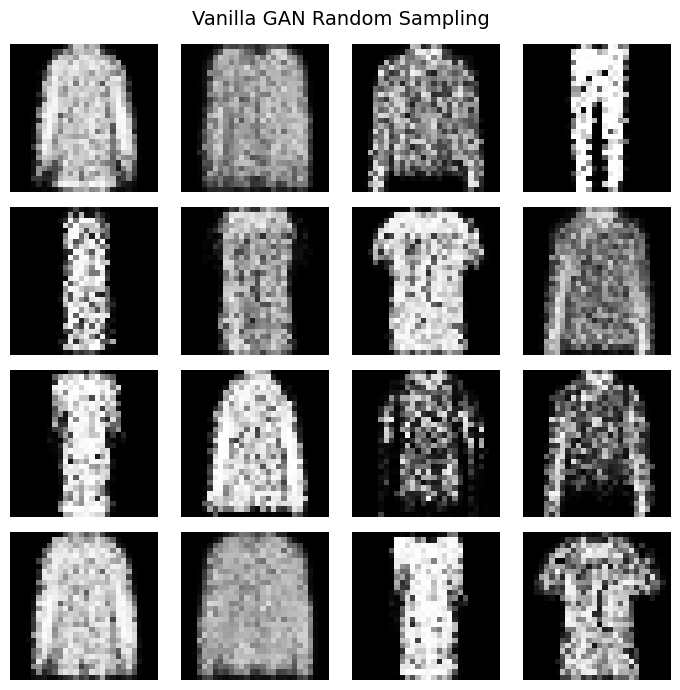

Saved image to: /content/drive/MyDrive/Model_Comparison/outputs/vanilla_gan/random_sampling.png


In [ ]:
# Random Sampling

generator.eval()

with torch.no_grad():
    generated_images = generator(fixed_noise)

fig, axes = plt.subplots(
    4, 4,
    figsize=(7, 7)
)

for i, ax in enumerate(axes.flat):

    image = (
        generated_images[i, 0]
        .detach()
        .cpu()
        .numpy()
    )

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

fig.suptitle(
    "Vanilla GAN Random Sampling",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "random_sampling.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved image to:", OUTPUT_DIR / "random_sampling.png")


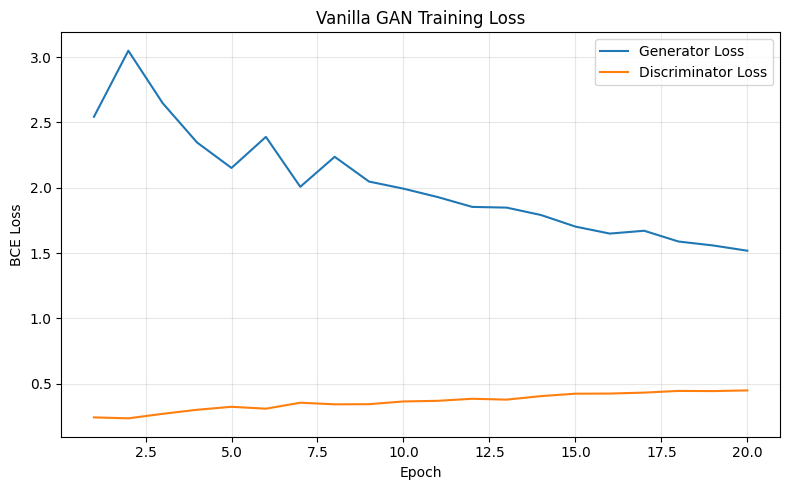

Saved image to: /content/drive/MyDrive/Model_Comparison/outputs/vanilla_gan/training_loss.png


In [ ]:
# Training Loss

fig, ax = plt.subplots(figsize=(8, 5))

epochs = range(1, GAN_EPOCHS + 1)

ax.plot(
    epochs,
    gan_g_losses,
    label="Generator Loss"
)

ax.plot(
    epochs,
    gan_d_losses,
    label="Discriminator Loss"
)

ax.set_title("Vanilla GAN Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE Loss")

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved image to:", OUTPUT_DIR / "training_loss.png")
